In [1]:
# From arb
from pynq import Overlay
import xrfclk
from pynq import PL
import pynq
from pynq.lib import AxiGPIO

# From ADC part
from adc_scope import AdcScope

import xrfdc
import matplotlib.pyplot as plt
%matplotlib inline

# From AWG part
import numpy as np
from rfsoc_awg import *      # AWG, Pulse and the unit helpers ns, us, kHz, MHz, GHz

In [2]:
PL.reset()
xrfclk.set_ref_clks(lmk_freq=245.76, lmx_freq=491.52)   #Programs the oscillators on the board to produce the appropriate clock signals

ol = Overlay("awg_adc.bit") #Load the FPGA bit file 

Window = 0.9993 us  (9824 samples, 614 clock cycles)  [requested 1.0000 us]


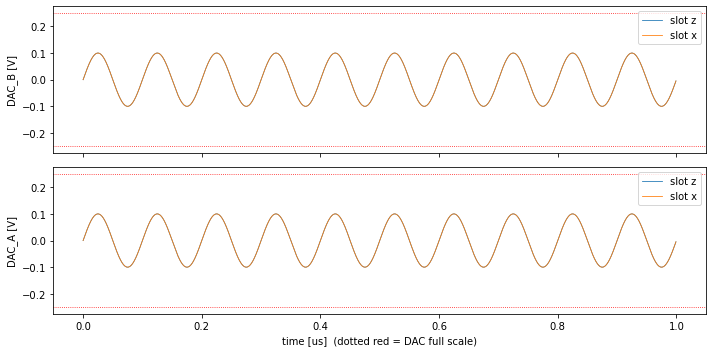

Asserting external reset (low)...
Releasing external reset (high)...
DMA upload took 0.0073 s
Started: ['DAC_A', 'DAC_B']
Stopped.
DMA upload took 0.0116 s
Started: ['DAC_A', 'DAC_B']


In [3]:
## DAC

# Length of ONE waveform slot. It is rounded to a multiple of 1.6276 ns; the real value is printed.
# (Max 26.67 us.)
awg = AWG(window=1 * us, bitfile=ol)
# chirp = 0.1 * np.sin(2 * np.pi * (50 * MHz * awg.t + 0.5 * (20 * MHz / awg.window/4) * awg.t**2))   # linear sweep 50 -> 70 MHz
# tau = 350 * ns                                  
# awg.set_waveform("DAC_A", "z", Pulse(amp=0.1, start=1 * us,         duration=100 * ns))
# awg.set_waveform("DAC_B", "z", Pulse(amp=0.1, start=1 * us + tau,   duration=100 * ns))

# my_wave = lambda t, T: np.sin(2 * np.pi * 30 * MHz * t) * np.cos(2 * np.pi * 1 * MHz * t)
#awg.set_waveform("DAC_A", "z", Pulse(wave=my_wave, amp=0.1, start=2 * us, duration=5 * us, shape="gauss"))

sine10M = lambda t, T: 0.1 * np.sin(2 * np.pi * 10 * MHz * t)
sine10M = sine10M(awg.t, awg.window)

awg.set_waveform("DAC_B", "x", sine10M)
awg.set_waveform("DAC_A", "x", sine10M)
awg.set_waveform("DAC_B", "z", sine10M)
awg.set_waveform("DAC_A", "z", sine10M)

awg.plot()
plt.show()

awg.connect()    # load bitstream, program clocks, reset the AWG logic
awg.upload()     # send waveforms + length to the board RAM
awg.start()      # enable the outputs

# Bug that we need it?
awg.play()       # = stop -> upload -> start

In [4]:
sc = AdcScope(ol)

{'triggered': True, 'trig_time_ns': 162.76041666666669, 't0_index': 136.0} 0.0005315693455287127 -0.002288818359375 0.00189208984375


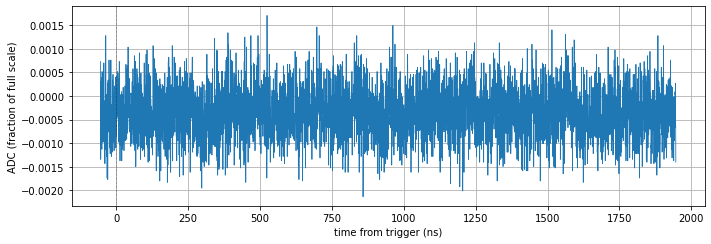

In [21]:
sc.configure(trigger="awg2", pre_ns=50, length_ns=2000)
t, y = sc.acquire()
print(sc.last, y.std(), y.min(), y.max())
t, y = sc.acquire(); sc.plot(t, y)

True 0.0005347297359018345


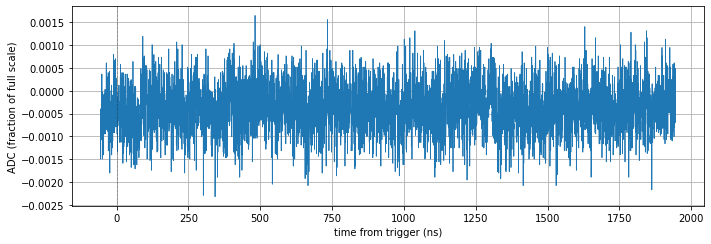

In [26]:
sc.configure(trigger="rising", level=0.0, pre_ns=50, length_ns=2000)
t, y = sc.acquire()
print(sc.last["triggered"], y.std())
t, y = sc.acquire(); sc.plot(t, y)

False 0.0005366862917462181


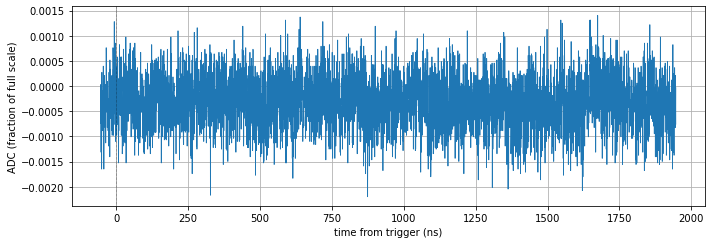

In [5]:
sc.configure(trigger="rising", level=0.05, pre_ns=50, length_ns=2000)
t, y = sc.acquire()
print(sc.last["triggered"], y.std())
t, y = sc.acquire(); sc.plot(t, y)

# Quick accesses

In [24]:
awg.stop()

Stopped.


In [25]:
awg.play()       # = stop -> upload -> start

Stopped.
DMA upload took 0.0114 s
Started: ['DAC_A', 'DAC_B']
